# Sheep, wolves, grass, and survival

<a target="_blank" href="https://colab.research.google.com/github/DACSS-Complexity/s5_sheep_wolves_experiment/blob/main/index.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


We compare 100 sheep / 100 wolves with 400 sheep / 400 wolves in the same world, using the same reproduction probabilities and grass-regrowth settings.

1. **Does a larger initial population prevent mutual extinction?**
2. **Do different grass scenarios affect animal survival?**

**Mutual extinction** means both animal populations are zero. The survival curves estimate the probability that at least one population remains. This is different from both species surviving together.

## Load the two experiments

Each row is the final observation of one simulation run. Each complete combination of grass-regrowth time, sheep reproduction probability, and wolf reproduction probability has three repetitions.

The analysis uses every run. Change the links below to compare other exports with the same experiment design.

In [1]:
import pandas as pd

base = "https://raw.githubusercontent.com/DACSS-Complexity/s5_sheep_wolves_experiment/main/"

exp_100 = pd.read_csv(base + "Wolf_Sheep_experiment_100_100-table.csv", skiprows=6)
exp_400 = pd.read_csv(base + "Wolf_Sheep_experiment_400_400-table.csv", skiprows=6)

exp_100["config"] = "100/100"
exp_400["config"] = "400/400"
data = pd.concat([exp_100, exp_400], ignore_index=True)

data = data.rename(columns={
    "[run number]": "run",
    "wolf-reproduce-probability": "wolf_probability",
    "sheep-reproduce-probability": "sheep_probability",
    "grass-regrowth-time": "grass_time",
    "[step]": "step",
    "land_with_grass": "grass_percent",
    "count sheep": "sheep",
    "count wolves": "wolves",
})

## 1. Does a larger initial population prevent mutual extinction?

First count how the runs ended. The categories below are mutually exclusive: each run appears in exactly one column. Compare the two rows to see whether starting with more animals is associated with fewer mutual extinctions.

In [2]:
from IPython.display import display, Markdown

CONFIGS = ["100/100", "400/400"]

data["both_extinct"] = (data.sheep == 0) & (data.wolves == 0)
data["sheep_only"] = (data.sheep > 0) & (data.wolves == 0)
data["wolves_only"] = (data.sheep == 0) & (data.wolves > 0)
data["both_remain"] = (data.sheep > 0) & (data.wolves > 0)

OUTCOMES = {
    "both_extinct": "Both extinct",
    "sheep_only": "Sheep only",
    "wolves_only": "Wolves only",
    "both_remain": "Both remain",
}
q1_counts = data.groupby("config")[list(OUTCOMES)].sum().reindex(CONFIGS).astype(int)
q1_counts = q1_counts.rename(columns=OUTCOMES)
q1_counts.insert(0, "Runs", data.groupby("config").size().reindex(CONFIGS))
display(q1_counts)

,Runs,Both extinct,Sheep only,Wolves only,Both remain
config,,,,,
100/100,1215,931,284,0,0
400/400,1215,1155,60,0,0


In [3]:
lines = ["**Interpretation:**"]
for label in CONFIGS:
    row = q1_counts.loc[label]
    lines.append(
        f"**{label}:** both populations are extinct in **{int(row['Both extinct'])}/{int(row.Runs)} runs "
        f"({row['Both extinct']/row.Runs:.1%})**. Both species remain in **{int(row['Both remain'])} runs**."
    )
rates = q1_counts['Both extinct'] / q1_counts.Runs
if rates['400/400'] > rates['100/100']:
    lines.append("**No: the larger initial population does not prevent mutual extinction. It is more frequent in 400/400 in this experiment.**")
elif rates['400/400'] < rates['100/100']:
    lines.append("Mutual extinction is less frequent in 400/400, although the larger initial population does not eliminate it.")
else:
    lines.append("The two configurations have the same observed mutual-extinction frequency.")
lines.append("The same world size is used, so increasing the initial numbers also increases initial animal density.")
display(Markdown("\n\n".join(lines)))

**Interpretation:**

**100/100:** both populations are extinct in **931/1215 runs (76.6%)**. Both species remain in **0 runs**.

**400/400:** both populations are extinct in **1155/1215 runs (95.1%)**. Both species remain in **0 runs**.

**No: the larger initial population does not prevent mutual extinction. It is more frequent in 400/400 in this experiment.**

The same world size is used, so increasing the initial numbers also increases initial animal density.

## 2. Do different grass scenarios affect animal survival?

We compare five grass-regrowth times within each initial-population configuration. A smaller value means faster regrowth.

**How to read the plots:**

- Each curve represents one grass scenario, using the same reproduction-probability grid.
- The x-axis shows ticks. A higher curve means a greater estimated probability that at least one animal population remains.
- An event occurs when **both animal populations are extinct**. Runs with animals remaining at tick 1500 are right-censored.

The curves describe avoidance of mutual extinction, not coexistence of both species. Wolves are absent at every recorded endpoint in these data.

In [4]:
import matplotlib.pyplot as plt

try:
    from lifelines import KaplanMeierFitter
except ModuleNotFoundError:
    get_ipython().run_line_magic("pip", "install -q lifelines")
    from lifelines import KaplanMeierFitter

TIME_LIMIT = 1500

# The supplied experiments do not stop early with animals still present.
if ((data.step < TIME_LIMIT) & ~data.both_extinct).any():
    raise ValueError("Some runs stop early with animals remaining. Check the stopping rule before interpreting survival to tick 1500.")

def plot_grass_survival(config):
    sub = data[data.config == config]
    fig, ax = plt.subplots(figsize=(10, 5))
    for grass, group in sub.groupby("grass_time"):
        kmf = KaplanMeierFitter()
        kmf.fit(group.step, event_observed=group.both_extinct, label=f"{grass:g}")
        kmf.plot_survival_function(
            ax=ax, ci_show=False,
            linestyle="--" if grass in (175, 225) else "-"
        )
    ax.set_title(f"Grass scenarios: initial sheep/wolves = {config}")
    ax.set_xlabel("Ticks")
    ax.set_ylabel("Probability at least one animal population remains")
    ax.set_xlim(0, TIME_LIMIT)
    ax.set_ylim(0, 1.02)
    ax.legend(title="Grass-regrowth time")
    fig.tight_layout()
    plt.show()

### Initial population: 100/100

**Does faster grass regrowth keep animals present for longer when we start with 100 sheep and 100 wolves?**

Follow each curve from left to right. Compare faster regrowth (150) with slower regrowth (250), then examine the intermediate scenarios.

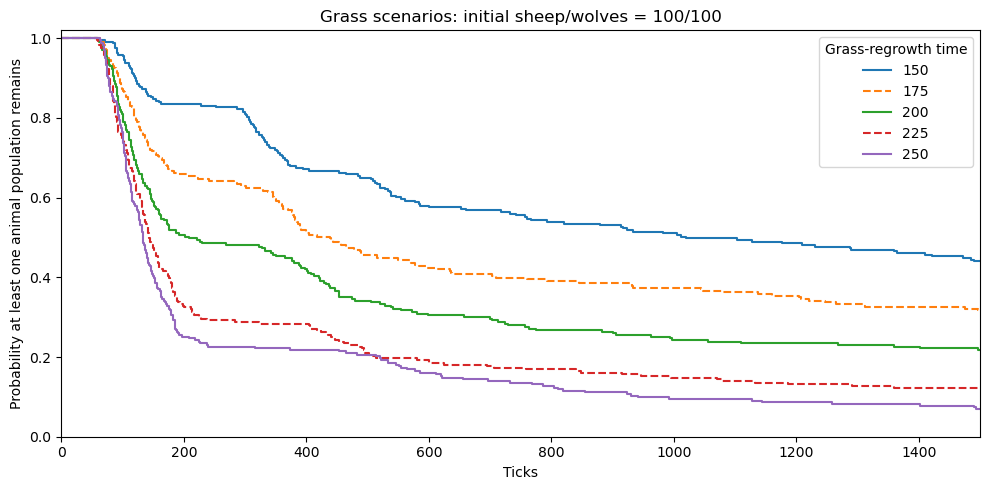

In [5]:
plot_grass_survival("100/100")

**Interpretation:** Faster grass regrowth generally produces higher curves. At the same tick, more runs have avoided mutual extinction under faster regrowth. Slower regrowth is associated with earlier and more frequent mutual extinction.

### Initial population: 400/400

**Does the same grass-regrowth pattern appear when we start with 400 sheep and 400 wolves?**

Read the curves in the same way. Both plots use the same time and probability scales.

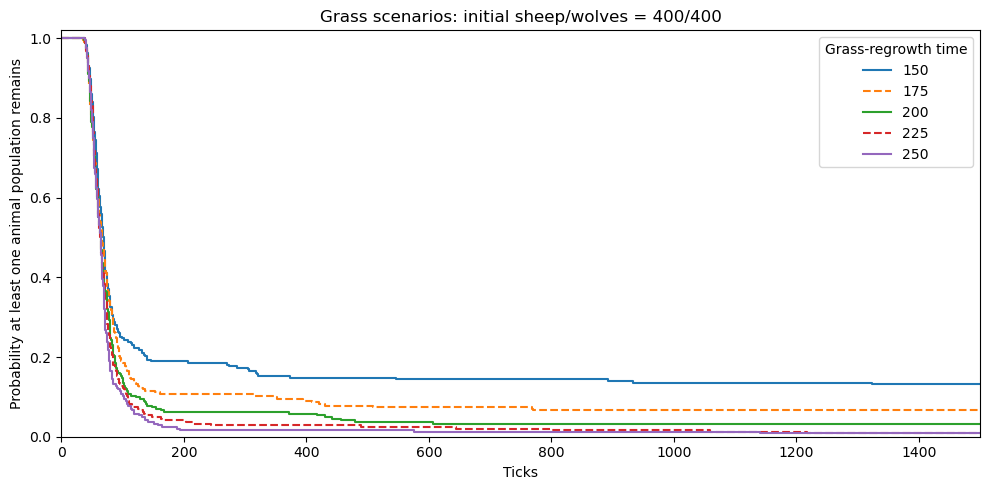

In [6]:
plot_grass_survival("400/400")

**Interpretation:** The curves drop rapidly across the grass scenarios. Faster regrowth is generally associated with longer survival, but mutual extinction remains common. Compared with the 100/100 plot, these curves fall earlier and leave fewer runs with animals remaining.

Across the tested grass scenarios, no run retains both species at tick 1500.

## 3. Pairwise log-rank tests

Compare grass-regrowth times **150, 200, and 250**, separately for each initial population: **150 vs 200**, **150 vs 250**, and **200 vs 250**.

The null hypothesis for each pair is that its two survival distributions are the same. We show the raw p-value and a **Holm-adjusted p-value**, correcting for the three comparisons within that configuration. Use the adjusted p-value when interpreting the results at the 5% level.

The test assesses differences between distributions. Use the curves to see which scenario retains animals for longer.

In [7]:
from itertools import combinations
from lifelines.statistics import logrank_test

def holm_adjust(p_values):
    ordered = p_values.sort_values()
    factors = pd.Series(range(len(ordered), 0, -1), index=ordered.index)
    return (ordered * factors).cummax().clip(upper=1).reindex(p_values.index)

def compare_grass_curves(config):
    sub = data[data.config == config]
    rows = []
    for grass_a, grass_b in combinations([150, 200, 250], 2):
        a = sub[sub.grass_time == grass_a]
        b = sub[sub.grass_time == grass_b]
        result = logrank_test(a.step, b.step,
                              event_observed_A=a.both_extinct,
                              event_observed_B=b.both_extinct)
        rows.append({"Grass A": grass_a, "Grass B": grass_b,
                     "Chi-squared": result.test_statistic, "p-value": result.p_value})
    table = pd.DataFrame(rows)
    table["Holm-adjusted p"] = holm_adjust(table["p-value"])
    table["Evidence of difference (5%)"] = table["Holm-adjusted p"] < 0.05
    return table

pairwise_tests = {config: compare_grass_curves(config) for config in CONFIGS}

### Initial population: 100/100

In [8]:
table = pairwise_tests["100/100"]
display(table.style.format({"Chi-squared": "{:.2f}", "p-value": "{:.3g}", "Holm-adjusted p": "{:.3g}"}))

,Grass A,Grass B,Chi-squared,p-value,Holm-adjusted p,Evidence of difference (5%)
0,150,200,45.40,1.6e-11,3.21e-11,True
1,150,250,158.44,2.48e-36,7.45e-36,True
2,200,250,27.27,1.77e-07,1.77e-07,True


In [9]:
table = pairwise_tests["100/100"]
count = int(table["Evidence of difference (5%)"].sum())
text = f"**Interpretation:** {count} of the {len(table)} pairs provide evidence of different survival distributions after Holm adjustment."
remaining = table[~table["Evidence of difference (5%)"]]
if not remaining.empty:
    pairs = ", ".join(f"{int(row['Grass A'])} vs {int(row['Grass B'])}" for _, row in remaining.iterrows())
    text += f" Comparisons without sufficient evidence of a difference are **{pairs}**. Their adjusted p-values do not establish a difference at the 5% level; this does not establish identical survival distributions."
text += " These comparisons pool the same reproduction-probability grid within each grass scenario."
display(Markdown(text))

**Interpretation:** 3 of the 3 pairs provide evidence of different survival distributions after Holm adjustment. These comparisons pool the same reproduction-probability grid within each grass scenario.

### Initial population: 400/400

In [10]:
table = pairwise_tests["400/400"]
display(table.style.format({"Chi-squared": "{:.2f}", "p-value": "{:.3g}", "Holm-adjusted p": "{:.3g}"}))

,Grass A,Grass B,Chi-squared,p-value,Holm-adjusted p,Evidence of difference (5%)
0,150,200,13.42,0.000248,0.000497,True
1,150,250,29.44,5.78e-08,1.73e-07,True
2,200,250,3.77,0.0521,0.0521,False


In [11]:
table = pairwise_tests["400/400"]
count = int(table["Evidence of difference (5%)"].sum())
text = f"**Interpretation:** {count} of the {len(table)} pairs provide evidence of different survival distributions after Holm adjustment."
remaining = table[~table["Evidence of difference (5%)"]]
if not remaining.empty:
    pairs = ", ".join(f"{int(row['Grass A'])} vs {int(row['Grass B'])}" for _, row in remaining.iterrows())
    text += f" Comparisons without sufficient evidence of a difference are **{pairs}**. Their adjusted p-values do not establish a difference at the 5% level; this does not establish identical survival distributions."
text += " These comparisons pool the same reproduction-probability grid within each grass scenario."
display(Markdown(text))

**Interpretation:** 2 of the 3 pairs provide evidence of different survival distributions after Holm adjustment. Comparisons without sufficient evidence of a difference are **200 vs 250**. Their adjusted p-values do not establish a difference at the 5% level; this does not establish identical survival distributions. These comparisons pool the same reproduction-probability grid within each grass scenario.

Each configuration is treated as a separate family of three tests. These results concern the simulated scenarios and do not validate the model against a real ecosystem.

## What have we learned?

1. **Initial density:** in the same-sized world, mutual extinction is more frequent in 400/400 than in 100/100.
2. **Grass regrowth:** faster regrowth generally produces higher survival curves. Survival is lower in 400/400 across the tested grass scenarios.
3. **Log-rank comparisons:** after Holm adjustment, the tests support differences for all three selected pairs in 100/100. In 400/400, the tests support differences for 150 vs 200 and 150 vs 250, but not for 200 vs 250 at the 5% level.

Wolves are absent at every recorded endpoint. Runs retaining animals to tick 1500 retain sheep, rather than both species.

### Going further

Cox regression could examine how **initial density, grass-regrowth time, and both reproduction probabilities jointly relate to the rate of mutual extinction over time**.

It could also examine interactions, such as whether the association between grass regrowth and survival differs by initial density. Before interpreting the results, we would check the proportional-hazards assumption.

This would extend the analysis from comparing curves to examining several variables together.